In [6]:
# Q4B: K-Medoids on the credit card dataset; choose k by silhouette score.
# Source: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.preprocessing import StandardScaler


In [7]:
# Read the downloaded CSV. Sample reproducibly because exact pairwise
# distances over all 8,950 customers would use substantial memory.
credit = pd.read_csv("CC GENERAL.csv")
sample = credit.sample(n=800, random_state=42).reset_index(drop=True)
numeric = sample.drop(columns=["CUST_ID"])
X = SimpleImputer(strategy="median").fit_transform(numeric)
X_scaled = StandardScaler().fit_transform(X)
distances = pairwise_distances(X_scaled, metric="euclidean")
print("Full dataset:", credit.shape, "Clustering sample:", sample.shape)
print("Missing values in full dataset:", credit.isna().sum().sum())


Full dataset: (8950, 18) Clustering sample: (800, 18)
Missing values in full dataset: 314


In [8]:
# Alternating K-Medoids: each medoid is an actual customer record.
# Start with far-apart records, assign to nearest medoid, then minimize
# the sum of within-cluster distances. This uses no extra package.
def fit_kmedoids(distance_matrix, n_clusters, max_iter=30):
    n = len(distance_matrix)
    medoids = [int(np.argmin(distance_matrix.sum(axis=1)))]
    while len(medoids) < n_clusters:
        nearest = distance_matrix[:, medoids].min(axis=1)
        nearest[medoids] = -1
        medoids.append(int(np.argmax(nearest)))
    for _ in range(max_iter):
        labels = np.argmin(distance_matrix[:, medoids], axis=1)
        new_medoids = []
        for cluster in range(n_clusters):
            members = np.flatnonzero(labels == cluster)
            if len(members) == 0:
                raise ValueError("Empty cluster; try a smaller k")
            totals = distance_matrix[np.ix_(members, members)].sum(axis=1)
            new_medoids.append(int(members[np.argmin(totals)]))
        if new_medoids == medoids:
            break
        medoids = new_medoids
    labels = np.argmin(distance_matrix[:, medoids], axis=1)
    return labels, medoids


k=2: silhouette=0.812
k=3: silhouette=0.750
k=4: silhouette=0.312
k=5: silhouette=0.316
k=6: silhouette=0.295


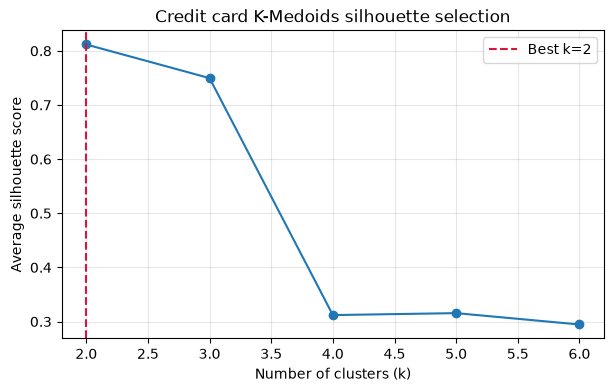

In [9]:
# The highest average silhouette score determines k for this sample.
k_values = range(2, 7)
scores = []
for k in k_values:
    labels, _ = fit_kmedoids(distances, k)
    score = silhouette_score(distances, labels, metric="precomputed")
    scores.append(score)
    print(f"k={k}: silhouette={score:.3f}")
best_k = list(k_values)[int(np.argmax(scores))]
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), scores, marker="o")
plt.axvline(best_k, color="crimson", linestyle="--", label=f"Best k={best_k}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.title("Credit card K-Medoids silhouette selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Cluster sizes: {0: 798, 1: 2}
Medoid customer IDs: ['C16594', 'C10574']


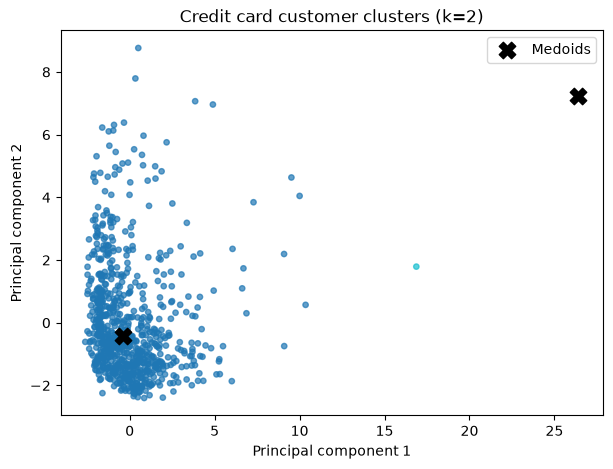

In [10]:
# Show the selected medoids and a two-dimensional view of the clusters.
labels, medoids = fit_kmedoids(distances, best_k)
print("Cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())
print("Medoid customer IDs:", sample.loc[medoids, "CUST_ID"].tolist())
points_2d = PCA(n_components=2).fit_transform(X_scaled)
plt.figure(figsize=(7, 5))
plt.scatter(points_2d[:, 0], points_2d[:, 1], c=labels, cmap="tab10", s=15, alpha=0.7)
plt.scatter(points_2d[medoids, 0], points_2d[medoids, 1],
            c="black", marker="X", s=140, label="Medoids")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title(f"Credit card customer clusters (k={best_k})")
plt.legend()
plt.show()
